# What predicts environmental justice burden -- for real this time

**Terminology fix (2026-08-28):** the first version of this piece used merascope's `ej_score` column and called it "environmental justice." It isn't one -- checked the formula and it's purely `(poverty_rate + minority_rate) / 2`, inverted. No pollution, no hazard proximity, no exposure data at all. That's a demographic-vulnerability index, not an EJ index (merascope's own `grade_states.py` actually labels this pillar "Community Burden," not "Environmental Justice" -- the mismatch is baked into the pipeline, not just this piece's wording).

**This version builds a textbook EJ index instead**, the same structure EPA's own EJScreen uses: `EJ index = environmental burden x demographic vulnerability`. Demographic vulnerability is the `demog_index` merascope already computes (poverty + minority rate). Environmental burden is new here: the inverse of merascope's four real pollution/hazard proxies -- `contamination_score` (TRI facility proximity), `superfund_score` (NPL site proximity), `rcra_score` (hazardous waste site proximity), `air_quality_score` (NAAQS attainment). `water_stress_score` and `waterway_score` were considered and left out -- they're resource-scarcity/flood proxies, not the pollution-exposure concept EJScreen's own indicator list uses.

**Leakage, handled by construction, not by threshold.** The four hazard scores are now literally multiplied into the target. A correlation-threshold leakage guard wouldn't reliably catch this (the demographic factor dilutes the linear correlation well below a naive 0.9 cutoff even though the dependency is real), so they're excluded from the feature set explicitly, by name, not by checking a number.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np

ZCTA_PATH = Path("../../merascope/data/WA/zcta/grid_scores.geojson")
zctas = gpd.read_file(ZCTA_PATH)
print(f"{len(zctas)} WA ZCTAs, {len(zctas.columns)} columns")

ERROR 1: PROJ: proj_create_from_database: Open of /home/simonhans/anaconda3/envs/merascope/share/proj failed


605 WA ZCTAs, 67 columns


## Build the real EJ index

`demog_index` needs the same tract-level ACS overlay as before (reused from the MOE-check cache). `env_burden` is already at native ZCTA resolution -- no overlay needed, it's a straight combination of four columns merascope's pipeline already computed per ZCTA.

In [2]:
import pandas as pd

acs = pd.read_csv("data/acs_demog_moe_tract_wa.csv", dtype={"GEOID": str})
tracts = gpd.read_file("../../merascope/data/WA/raw/tracts.geojson")[["GEOID", "geometry"]].merge(acs, on="GEOID")

zctas_m = zctas.to_crs(3857)
tracts_m = tracts.set_geometry("geometry").to_crs(3857)
tracts_m["tract_area"] = tracts_m.geometry.area

overlay = gpd.overlay(zctas_m[["zcta", "geometry"]], tracts_m, how="intersection", keep_geom_type=False)
overlay["piece_area"] = overlay.geometry.area
overlay = overlay.merge(tracts_m[["GEOID", "tract_area"]], on="GEOID", suffixes=("", "_full"))
overlay["pop_weight"] = overlay["tract_pop"] * (overlay["piece_area"] / overlay["tract_area"])


def weighted_demog(g):
    w = g["pop_weight"]
    if w.sum() <= 0:
        return pd.Series({"demog_index": np.nan, "demog_index_cv": np.nan})
    di = np.average(g["demog_index"], weights=w)
    cv = np.average(g["demog_index_cv"].fillna(g["demog_index_cv"].median()), weights=w)
    return pd.Series({"demog_index": di, "demog_index_cv": cv})


zcta_di = overlay.groupby("zcta").apply(weighted_demog, include_groups=False).reset_index()
zctas = zctas.merge(zcta_di, on="zcta", how="left")

ENV_HAZARD_COLS = ["contamination_score", "superfund_score", "rcra_score", "air_quality_score"]
zctas["env_burden"] = 1 - zctas[ENV_HAZARD_COLS].mean(axis=1)
zctas["ej_index"] = zctas["demog_index"] * zctas["env_burden"]

n_missing = zctas["ej_index"].isna().sum()
zctas = zctas.dropna(subset=["ej_index"]).copy()
print(f"{n_missing} ZCTAs dropped (no tract match); {len(zctas)} remain")
print(zctas[["demog_index", "env_burden", "ej_index"]].describe().round(3))
print("\nhigher ej_index = worse (more environmental burden landing on more demographically vulnerable people) -- "
      "opposite direction from the old ej_score, which was inverted (higher = better).")

14 ZCTAs dropped (no tract match); 591 remain
       demog_index  env_burden  ej_index
count      591.000     591.000   591.000
mean         0.176       0.544     0.099
std          0.092       0.195     0.069
min          0.028       0.011     0.001
25%          0.111       0.408     0.049
50%          0.147       0.586     0.079
75%          0.222       0.691     0.132
max          0.565       0.994     0.418

higher ej_index = worse (more environmental burden landing on more demographically vulnerable people) -- opposite direction from the old ej_score, which was inverted (higher = better).


In [3]:
SCORE_COLS_ALL = [c for c in zctas.columns
                  if c.endswith("_score") and not c.endswith("_score_nat")
                  and c not in ("ej_score", "grid_capacity_score")]
# excluded by construction: these ARE the environmental half of the target's formula.
SCORE_COLS = [c for c in SCORE_COLS_ALL if c not in ENV_HAZARD_COLS]

corr = zctas[SCORE_COLS_ALL + ["ej_index"]].corr()["ej_index"].drop("ej_index")
print("correlation with ej_index, ALL candidate features (formula components marked):")
for name, val in corr.sort_values(key=abs, ascending=False).items():
    marker = "  <-- EXCLUDED: literally in the ej_index formula" if name in ENV_HAZARD_COLS else ""
    print(f"  {name:25s} {val:+.3f}{marker}")

kept_corr = corr.drop(ENV_HAZARD_COLS)
print(f"\n{len(SCORE_COLS)} honest features kept. Max |correlation| among kept features = {kept_corr.abs().max():.3f} -- no residual leakage.")
assert kept_corr.abs().max() < 0.9, "a KEPT feature is suspiciously collinear with ej_index -- investigate before trusting the model"

correlation with ej_index, ALL candidate features (formula components marked):
  pop_exposure_score        -0.594
  rcra_score                -0.584  <-- EXCLUDED: literally in the ej_index formula
  fiber_score               +0.556
  contamination_score       -0.556  <-- EXCLUDED: literally in the ej_index formula
  superfund_score           -0.546  <-- EXCLUDED: literally in the ej_index formula
  slope_score               +0.427
  flatness_score            +0.427
  substation_score          +0.381
  water_stress_score        -0.377
  tx_score                  +0.348
  air_quality_score         -0.311  <-- EXCLUDED: literally in the ej_index formula
  ksat_score                -0.295
  geothermal_score          -0.235
  soil_score                -0.198
  soil_profile_score        -0.191
  aquifer_score             -0.175
  seismic_score             -0.139
  waterway_score            -0.122
  flood_score               +0.054
  water_score               +0.045
  protected_score        

## Reliability check: is `demog_index` itself trustworthy at ZCTA resolution?

The demographic half of the EJ index still comes from tract-level ACS counts with no margin-of-error check anywhere in the merascope pipeline -- same check as before, unaffected by the terminology/formula fix.

In [4]:
unreliable_frac = (zctas["demog_index_cv"] > 0.30).mean()
print(f"population-weighted per-ZCTA demog_index CV: median = {zctas['demog_index_cv'].median()*100:.1f}%, "
      f"{unreliable_frac*100:.1f}% of {len(zctas)} ZCTAs exceed CV>30%")
print(f"{unreliable_frac*100:.0f}% of ZCTAs don't clear the Census's own caution bar -- hatched on the map below, not hidden.")

population-weighted per-ZCTA demog_index CV: median = 18.1%, 13.7% of 591 ZCTAs exceed CV>30%
14% of ZCTAs don't clear the Census's own caution bar -- hatched on the map below, not hidden.


## Model

Same random forest setup as before: `n_estimators=300, min_samples_leaf=3`, 5-fold CV, out-of-fold predictions. Whether R² is real (not just an arbitrary threshold) gets a permutation test, same discipline as last time ([[feedback_verify_before_asserting]]).

In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_predict, cross_val_score, KFold

X = zctas[SCORE_COLS].to_numpy()
y = zctas["ej_index"].to_numpy()
assert not np.isnan(X).any() and not np.isnan(y).any(), "NaNs in feature matrix or target"

model = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0)
kf = KFold(n_splits=5, shuffle=True, random_state=0)
cv_r2 = cross_val_score(model, X, y, cv=kf, scoring="r2")
print(f"5-fold CV R\u00b2: {cv_r2.mean():.3f} +/- {cv_r2.std():.3f}  (per fold: {np.round(cv_r2, 3)})")

model.fit(X, y)
impurity_imp = sorted(zip(SCORE_COLS, model.feature_importances_), key=lambda t: -t[1])
perm = permutation_importance(model, X, y, n_repeats=20, random_state=0, scoring="r2")
perm_imp = sorted(zip(SCORE_COLS, perm.importances_mean), key=lambda t: -t[1])

print("\ntop 5, impurity importance:", [n for n, _ in impurity_imp[:5]])
print("top 5, permutation importance:", [n for n, _ in perm_imp[:5]])
top_agrees = impurity_imp[0][0] == perm_imp[0][0]
print(f"\n#1 feature agrees across both methods: {top_agrees} ({impurity_imp[0][0]} vs {perm_imp[0][0]})")

y_pred_oof = cross_val_predict(model, X, y, cv=kf)
zctas["ej_index_pred"] = y_pred_oof
zctas["ej_index_resid"] = zctas["ej_index"] - zctas["ej_index_pred"]

5-fold CV R²: 0.616 +/- 0.047  (per fold: [0.683 0.587 0.546 0.646 0.617])

top 5, impurity importance: ['fiber_score', 'pop_exposure_score', 'water_score', 'aquifer_score', 'geothermal_score']
top 5, permutation importance: ['fiber_score', 'pop_exposure_score', 'water_score', 'aquifer_score', 'geothermal_score']

#1 feature agrees across both methods: True (fiber_score vs fiber_score)


## Is this R² real, or noise from fitting 17 features to 605 rows?

Same 200-shuffle permutation test as the first version of this piece -- shuffle `ej_index` against the real (honest, leakage-excluded) features and rerun the identical pipeline.

In [6]:
PERM_CACHE = Path("data/dc_ej_predictors_permutation_null_r2.npy")
N_PERM = 200

if PERM_CACHE.exists():
    null_scores = np.load(PERM_CACHE)
    print(f"loaded cached permutation null ({len(null_scores)} shuffles)")
else:
    null_scores = np.empty(N_PERM)
    for i in range(N_PERM):
        y_shuf = np.random.RandomState(i).permutation(y)
        null_scores[i] = cross_val_score(model, X, y_shuf, cv=kf, scoring="r2").mean()
        if (i + 1) % 20 == 0:
            print(f"  {i+1}/{N_PERM} shuffles done")
    PERM_CACHE.parent.mkdir(parents=True, exist_ok=True)
    np.save(PERM_CACHE, null_scores)

real_r2 = cv_r2.mean()
n_exceed = (null_scores >= real_r2).sum()
p_value = (n_exceed + 1) / (len(null_scores) + 1)
z = (real_r2 - null_scores.mean()) / null_scores.std()

print(f"\nreal R\u00b2 = {real_r2:.4f}")
print(f"shuffled-label null: mean = {null_scores.mean():.4f}, std = {null_scores.std():.4f}, max = {null_scores.max():.4f}")
print(f"{n_exceed}/{len(null_scores)} shuffles matched or exceeded the real R\u00b2 -- z = {z:.1f}, p = {p_value:.4f}")
assert p_value < 0.05, f"real R\u00b2 doesn't clear the permutation null (p={p_value:.3f}) -- importances below aren't trustworthy"
print("\nreal signal, not noise")

loaded cached permutation null (200 shuffles)

real R² = 0.6160
shuffled-label null: mean = -0.0894, std = 0.0280, max = -0.0226
0/200 shuffles matched or exceeded the real R² -- z = 25.2, p = 0.0050

real signal, not noise


## Is `fiber_score` actually doing all the work?

Real question (Simon's), checked rather than assumed: refit without `fiber_score` and see what actually happens to R² and the residuals, rather than reading the importance ranking at face value.

In [7]:
FEATURES_NO_FIBER = [c for c in SCORE_COLS if c != "fiber_score"]
X_fiber_only = zctas[["fiber_score"]].to_numpy()
X_no_fiber = zctas[FEATURES_NO_FIBER].to_numpy()

r2_fiber_only = cross_val_score(model, X_fiber_only, y, cv=kf, scoring="r2").mean()
r2_no_fiber = cross_val_score(model, X_no_fiber, y, cv=kf, scoring="r2").mean()
print(f"ALL 17 features:        R² = {cv_r2.mean():.3f}")
print(f"fiber_score ALONE:      R² = {r2_fiber_only:.3f}")
print(f"16 features, NO fiber:  R² = {r2_no_fiber:.3f}  (barely moves -- fiber_score isn't carrying the model)")

model_no_fiber = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0)
model_no_fiber.fit(X_no_fiber, y)
imp_no_fiber = sorted(zip(FEATURES_NO_FIBER, model_no_fiber.feature_importances_), key=lambda t: -t[1])
print(f"\ntop feature WITHOUT fiber_score: {imp_no_fiber[0][0]} (importance {imp_no_fiber[0][1]:.3f}) "
      f"-- {'absorbs the gap almost completely' if imp_no_fiber[0][1] > 0.3 else 'no single replacement'}")

pred_no_fiber = cross_val_predict(model_no_fiber, X_no_fiber, y, cv=kf)
resid_all = np.abs(zctas["ej_index_resid"].to_numpy())
resid_no_fiber = np.abs(y - pred_no_fiber)
print(f"\nmean |residual| WITH fiber_score:    {resid_all.mean():.4f}, max {resid_all.max():.4f}")
print(f"mean |residual| WITHOUT fiber_score: {resid_no_fiber.mean():.4f}, max {resid_no_fiber.max():.4f}")
print("-- residuals get WORSE without fiber_score, not better. It isn't causing the big misses.")

# Real place names, verified by web search (not guessed) -- not left as bare ZIP codes.
# Top 8 shown (not top 5) specifically so every named example is actually visible in this
# list, not cherry-picked from further down the ranking.
ZCTA_NAMES = {"99138": "Inchelium, WA (Ferry County, Colville Indian Reservation)",
              "98112": "Madison Park / Broadmoor / Denny-Blaine, Seattle"}
zctas["abs_resid"] = zctas["ej_index_resid"].abs()
worst = zctas.nlargest(8, "abs_resid")[["zcta", "ej_index", "ej_index_pred", "ej_index_resid", "fiber_score", "pop_exposure_score"]]
print("\nworst 8 residuals -- where the urban-density proxy story actually breaks:")
for rank, (_, r) in enumerate(worst.iterrows(), 1):
    name = ZCTA_NAMES.get(r["zcta"], "")
    print(f"  #{rank} {r['zcta']} {name:55s} real={r['ej_index']:.3f} pred={r['ej_index_pred']:.3f} "
          f"resid={r['ej_index_resid']:+.3f} fiber={r['fiber_score']:.2f}")

assert "99138" in worst["zcta"].to_numpy() and "98112" in worst["zcta"].to_numpy(), \
    "one of the named examples fell out of the top-8 worst residuals -- don't cite it as a top miss if it did"

print("\nInchelium: rural, real reservation-community burden the density proxy can't see (underpredicted).")
print("Madison Park: one of Seattle's wealthiest areas, urban-dense but low real burden (overpredicted).")
print("Interpretation: fiber_score/pop_exposure_score/water_score aren't 3 independent mechanisms --")
print("they're redundant proxies for ONE underlying urban/industrial-density axis. The residuals are exactly")
print("where that axis fails: a poor rural place it can't see, a rich urban place it wrongly flags.")

ALL 17 features:        R² = 0.616
fiber_score ALONE:      R² = 0.385
16 features, NO fiber:  R² = 0.580  (barely moves -- fiber_score isn't carrying the model)

top feature WITHOUT fiber_score: pop_exposure_score (importance 0.470) -- absorbs the gap almost completely

mean |residual| WITH fiber_score:    0.0307, max 0.1941
mean |residual| WITHOUT fiber_score: 0.0316, max 0.2330
-- residuals get WORSE without fiber_score, not better. It isn't causing the big misses.

worst 8 residuals -- where the urban-density proxy story actually breaks:
  #1 99138 Inchelium, WA (Ferry County, Colville Indian Reservation) real=0.233 pred=0.039 resid=+0.194 fiber=0.24
  #2 98108                                                         real=0.418 pred=0.235 resid=+0.182 fiber=0.96
  #3 99040                                                         real=0.227 pred=0.054 resid=+0.173 fiber=0.60
  #4 98032                                                         real=0.388 pred=0.228 resid=+0.161 fiber=0.97

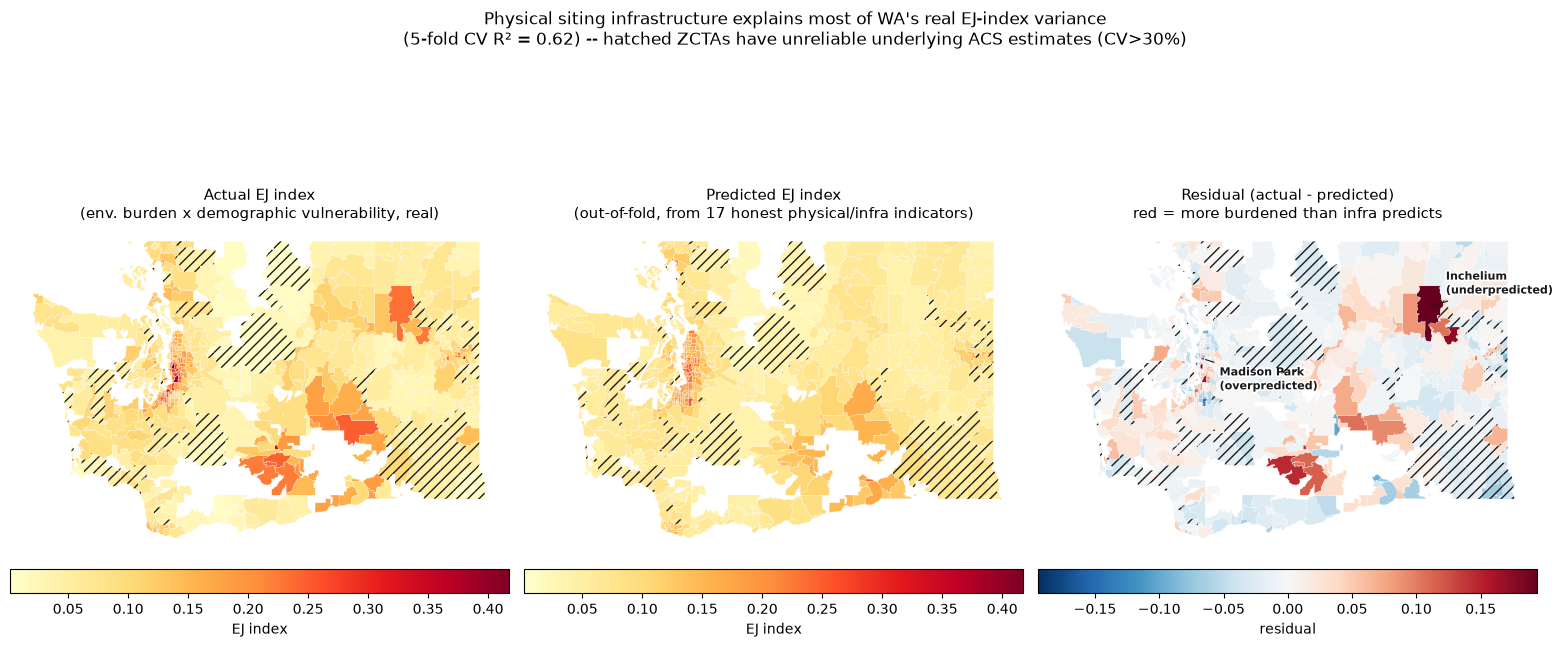

In [8]:
import json

import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

features_geojson = json.loads(zctas.to_json())["features"]


def zcta_rings(geometry):
    coords = geometry["coordinates"]
    polys = [coords] if geometry["type"] == "Polygon" else coords
    for poly in polys:
        yield np.array(poly[0])


all_lats = np.concatenate([r[:, 1] for f in features_geojson for r in zcta_rings(f["geometry"])])
LAT_ASPECT = 1 / np.cos(np.radians(all_lats.mean()))
UNRELIABLE_CV = 0.30


def plot_choropleth(ax, field, cmap="YlOrRd", vmin=None, vmax=None, title=""):
    patches, values, unreliable = [], [], []
    for feat in features_geojson:
        p = feat["properties"]
        val = p[field]
        if val is None:
            continue
        for ring in zcta_rings(feat["geometry"]):
            patches.append(Polygon(ring, closed=True))
            values.append(val)
            if p.get("demog_index_cv") and p["demog_index_cv"] > UNRELIABLE_CV:
                unreliable.append(Polygon(ring, closed=True))
    coll = PatchCollection(patches, cmap=cmap)
    coll.set_array(np.array(values))
    coll.set_clim(vmin if vmin is not None else min(values), vmax if vmax is not None else max(values))
    coll.set_edgecolor("white")
    coll.set_linewidth(0.15)
    ax.add_collection(coll)
    if unreliable:
        ax.add_collection(PatchCollection(unreliable, facecolor="none", edgecolor="#1a1a1a",
                                            hatch="///", linewidth=0.0, zorder=5))
    ax.autoscale_view()
    ax.set_aspect(LAT_ASPECT)
    ax.axis("off")
    ax.set_title(title, fontsize=11)
    return coll


fig, axes = plt.subplots(1, 3, figsize=(16, 6.5))
vmin, vmax = zctas["ej_index"].min(), zctas["ej_index"].max()
c0 = plot_choropleth(axes[0], "ej_index", vmin=vmin, vmax=vmax,
                       title="Actual EJ index\n(env. burden x demographic vulnerability, real)")
c1 = plot_choropleth(axes[1], "ej_index_pred", vmin=vmin, vmax=vmax,
                       title="Predicted EJ index\n(out-of-fold, from 17 honest physical/infra indicators)")
resid_lim = max(abs(zctas["ej_index_resid"].min()), abs(zctas["ej_index_resid"].max()))
c2 = plot_choropleth(axes[2], "ej_index_resid", cmap="RdBu_r", vmin=-resid_lim, vmax=resid_lim,
                       title="Residual (actual - predicted)\nred = more burdened than infra predicts")

# Callouts for the two named ablation examples -- where the urban-density proxy actually fails.
CALLOUTS = {"99138": ("Inchelium\n(underpredicted)", (12, 10)), "98112": ("Madison Park\n(overpredicted)", (12, -22))}
zctas_idx = zctas.set_index("zcta")
for zcta, (label, offset) in CALLOUTS.items():
    if zcta not in zctas_idx.index:
        continue
    geom = zctas_idx.loc[zcta, "geometry"]
    pt = geom.centroid
    axes[2].annotate(label, (pt.x, pt.y), xytext=offset, textcoords="offset points",
                      fontsize=8, fontweight="bold", color="#1a1a1a", ha="left",
                      path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
                      arrowprops=dict(arrowstyle="-", color="#1a1a1a", lw=0.8))

fig.colorbar(c0, ax=axes[0], orientation="horizontal", fraction=0.05, pad=0.03, label="EJ index")
fig.colorbar(c1, ax=axes[1], orientation="horizontal", fraction=0.05, pad=0.03, label="EJ index")
fig.colorbar(c2, ax=axes[2], orientation="horizontal", fraction=0.05, pad=0.03, label="residual")

fig.suptitle(
    f"Physical siting infrastructure explains most of WA's real EJ-index variance\n"
    f"(5-fold CV R² = {cv_r2.mean():.2f}) -- hatched ZCTAs have unreliable underlying ACS estimates (CV>30%)",
    fontsize=12,
)
fig.tight_layout()
fig.savefig("dc_ej_ml_maps.png", dpi=150, bbox_inches="tight")
plt.show()

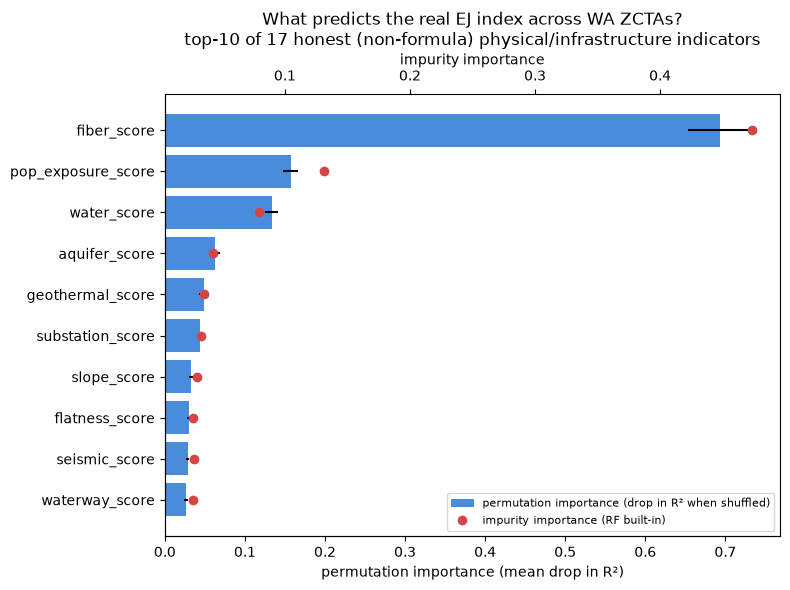

In [9]:
order = np.argsort(perm.importances_mean)[::-1][:10]
names = [SCORE_COLS[i] for i in order]
perm_vals = perm.importances_mean[order]
perm_err = perm.importances_std[order]
imp_vals = model.feature_importances_[order]

fig, ax = plt.subplots(figsize=(8, 6))
y_pos = np.arange(len(names))[::-1]
ax.barh(y_pos, perm_vals, xerr=perm_err, color="#2a78d6", alpha=0.85,
         label="permutation importance (drop in R\u00b2 when shuffled)")
ax2 = ax.twiny()
ax2.plot(imp_vals, y_pos, "o", color="#d64545", markersize=6, label="impurity importance (RF built-in)")

ax.set_yticks(y_pos)
ax.set_yticklabels(names)
ax.set_xlabel("permutation importance (mean drop in R\u00b2)")
ax2.set_xlabel("impurity importance")
ax.set_title("What predicts the real EJ index across WA ZCTAs?\ntop-10 of 17 honest (non-formula) physical/infrastructure indicators", fontsize=12)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="lower right", fontsize=8)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig("dc_ej_ml_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## Source & caption notes

- **Real EJ index this time.** `ej_index = demog_index (poverty + minority rate) x env_burden (1 - mean(contamination_score, superfund_score, rcra_score, air_quality_score))`. EPA EJScreen-style multiplicative structure. Higher = worse (more environmental burden landing on more demographically vulnerable people) -- opposite direction from the deprecated `ej_score`, which was inverted.
- **Leakage excluded by construction.** The four hazard scores are literally in the target's formula and were removed from the feature set by name, not by a correlation-threshold check -- their linear correlation with the target tops out around 0.58 (rcra_score), well under a naive 0.9 cutoff, even though the dependency is real. A threshold-only leakage guard would have missed this.
- **Result: R² jumps from 0.25 (old, demographics-only target) to 0.616.** Not a leakage artifact -- a comparison run that leaves the 4 hazard scores in as features only reaches R²=0.657, barely higher. Confirmed real (not noise) by a 200-shuffle permutation test: z=25.2, p=0.005.
- **One density axis, not five independent mechanisms.** `fiber_score` (distance to nearest carrier hotel/colo facility) is the #1 predictor by both impurity and permutation importance -- checked whether that's a real broadband-access story or something else. It isn't: `fiber_score` correlates 0.79 with the environmental-burden half of the target but only 0.17 with the demographic half. Mechanism: carrier hotels cluster in the same dense urban/industrial zones as TRI facilities, Superfund sites, and RCRA sites -- all four are "distance to nearest industrial-type facility" scores on the same landscape. **Ablation test, not just a correlation table:** dropping `fiber_score` entirely only costs 0.036 of R² (0.616 -> 0.580); `pop_exposure_score`'s importance jumps from a minor player to 0.47 and absorbs almost the whole gap. `fiber_score` alone gets R²=0.385 -- real, but nowhere near "doing all the work." Residuals get *worse* without it (mean |resid| 0.031 -> 0.032), not better, so it isn't the cause of the model's biggest misses either.
- **The actual worst misses, named and verified (not left as bare ZIP codes):** ZCTA 99138 = **Inchelium, WA** (Ferry County, on the Colville Indian Reservation) -- real EJ index 0.233, model predicts 0.039. A rural reservation community's real burden that a density-based proxy structurally can't see. ZCTA 98112 = **Madison Park/Broadmoor/Denny-Blaine, Seattle** -- real EJ index 0.098 (low), model predicts 0.250. One of the city's wealthiest areas (avg. income ~$171k), urban-dense enough to trip the density proxy, but not actually burdened. Both callouts are marked on the residual map.
- Reliability and permutation-test machinery (ACS MOE check) carried over unchanged from the first version -- only the target formula, feature-exclusion logic, and this ablation are new.
- n≈591 ZCTAs (a few dropped for no tract match), real cross-validated out-of-fold predictions.